## Climate Hazard Dataset Exploration

### Drought Hazard Dataset Exploration & Selection

**Project:** AI-Powered Climate Risk Intelligence Platform for Multi-Sector Decision Support in Germany

**Notebook:** 03_climate_dataset_exploration_drought_proxy_magnitude.ipynb

**Dataset:** Magnitude of Meteorological Droughts

**Description:** This dataset represents the magnitude of meteorological drought conditions across European NUTS-2 regions. It is derived from ERA5 reanalysis data and provides an annual measure of drought magnitude suitable for regional climate risk assessment.

**Purpose:** Selected as the drought hazard proxy for the AI-Powered Climate & ESG Risk Intelligence Platform because it provides a standardized measure of meteorological drought intensity across Germany.

**Hazard type:** Meteorological drought / drought proxy

**Spatial focus:** Germany

**Temporal focus:** 1990–2025

**Objective**

To explore, evaluate, and preprocess the Magnitude of Meteorological Droughts dataset for Germany and determine its suitability as a drought hazard proxy within the AI-Powered Climate & ESG Risk Intelligence Platform.

This notebook documents dataset characteristics, quality assessment, preprocessing decisions, visualization, and preparation for integration into the master climate hazard database.

### Import Libraries

In [ ]:
# ============================================================
# Climate Risk Intelligence Germany
# Dataset Exploration 03
# Dataset: Magnitude of Meteorological Droughts
# Variable: meteorological_droughts_magnitude
# Hazard Proxy: Meteorological Drought
# Author: Purity Mbaabu
# ============================================================

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

### Locate Dataset

In [14]:
# =======================================================
# Locate NetCDF dataset
# =======================================================

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

drought_file = (
    PROJECT_ROOT
    / "data"
    / "incoming"
    / "climate"
    / "20_magnitude_of_meteorological_droughts-reanalysis-yearly-layer-nuts_2-latitude-1940-2025-v2.0.nc"
)

print(drought_file)
print(drought_file.exists())

d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\incoming\climate\20_magnitude_of_meteorological_droughts-reanalysis-yearly-layer-nuts_2-latitude-1940-2025-v2.0.nc
True


### Load Dataset

In [15]:
# =======================================================
# Load NetCDF dataset
# =======================================================

ds_drought = xr.open_dataset(drought_file)

ds_drought


<xarray.Dataset> Size: 237kB
Dimensions:                            (nuts: 340, time: 86)
Coordinates:
  * nuts                               (nuts) object 3kB 'ITC4' ... 'UKI6'
  * time                               (time) datetime64[ns] 688B 1940-01-01 ...
    realization                        int64 8B ...
Data variables:
    meteorological_droughts_magnitude  (nuts, time) float64 234kB ...
Attributes:
    history:  Wed Jan 14 16:38:23 2026: /private/miniforge3/envs/ecde-data-de...
    NCO:      netCDF Operators version 5.3.6 (Homepage = http://nco.sf.net, C...

### Inspect Dataset

##### Step 1. Explore the variable

In [16]:
# =======================================================
# Inspect available variables
# =======================================================

list(ds_drought.data_vars)

['meteorological_droughts_magnitude']

##### Step 2. Explore the variable metadata

In [17]:
# =======================================================
# Inspect variable metadata
# =======================================================

ds_drought["meteorological_droughts_magnitude"].attrs

{'reduce_dims': ['lat', 'lon'],
 'units': '1',
 'comment': 'derived from 3 hourly ERA5 reanalysis'}

##### Step 3. Look at actual values

In [19]:
# =======================================================
# Inspect variable values
# =======================================================

ds_drought["meteorological_droughts_magnitude"]

<xarray.DataArray 'meteorological_droughts_magnitude' (nuts: 340, time: 86)> Size: 234kB
[29240 values with dtype=float64]
Coordinates:
  * nuts         (nuts) object 3kB 'ITC4' 'ITF1' 'ITF2' ... 'UKI4' 'UKI5' 'UKI6'
  * time         (time) datetime64[ns] 688B 1940-01-01 1941-01-01 ... 2025-01-01
    realization  int64 8B ...
Attributes:
    reduce_dims:  ['lat', 'lon']
    units:        1
    comment:      derived from 3 hourly ERA5 reanalysis

##### Step 4. Summary statistics

In [20]:
# ==============================================
# Generate summary statistics
# ==============================================

drought = ds_drought["meteorological_droughts_magnitude"]

print(f"Minimum           : {drought.min().values:.3f}")
print(f"Maximum           : {drought.max().values:.3f}")
print(f"Mean              : {drought.mean().values:.3f}")
print(f"Standard Deviation: {drought.std().values:.3f}")

Minimum           : 0.000
Maximum           : 29.550
Mean              : 3.127
Standard Deviation: 3.884


##### Step 5. Missing values

In [21]:

# ==============================================
# Check missing values
# ==============================================

missing_values = drought.isnull().sum()

print(f"Missing values: {missing_values.values}")

Missing values: 516


##### Step 6. Inspect one region

In [22]:
# =======================================================
# Inspect one region
# =======================================================

drought.isel(nuts=0)

<xarray.DataArray 'meteorological_droughts_magnitude' (time: 86)> Size: 688B
array([5.777139e+00, 7.080666e+00, 9.423334e+00, 1.053440e+01, 8.890704e+00,
       6.349416e+00, 4.218031e+00, 4.154166e+00, 2.730545e-01, 7.702369e+00,
       9.888431e+00, 9.524666e-01, 3.639063e+00, 5.256084e+00, 1.823650e+00,
       2.627602e+00, 2.032626e+00, 2.422380e+00, 8.165620e-01, 1.057974e+00,
       7.604757e-01, 5.143369e+00, 6.659008e+00, 9.236919e-02, 7.193359e-01,
       8.171742e-01, 4.686556e-02, 0.000000e+00, 0.000000e+00, 2.643378e+00,
       1.808690e+00, 4.170112e+00, 4.502842e-01, 1.493510e+00, 9.043829e-01,
       3.602441e-01, 3.203610e+00, 3.696713e-01, 1.866873e+00, 5.262438e-01,
       5.363615e-01, 1.198770e+00, 2.677754e-01, 3.915288e+00, 7.929343e-01,
       4.606607e+00, 6.137521e+00, 1.257585e+00, 2.684931e+00, 6.822851e+00,
       3.448721e+00, 1.251187e+00, 2.573947e+00, 1.401447e+00, 2.005107e-01,
       9.282784e-01, 1.284024e+00, 6.860745e+00, 6.702608e-01, 2.066876e+00,
       1.137258e+00, 2.006352e+00, 2.548723e+00, 1.226790e+01, 2.778358e+00,
       5.906092e+00, 5.760450e+00, 3.177382e+00, 3.357524e-01, 1.300740e+00,
       0.000000e+00, 1.189843e+00, 1.588032e+00, 6.609748e-02, 3.006433e-01,
       1.126889e+00, 2.082931e+00, 1.971390e+00, 3.227749e-01, 1.118705e+00,
       2.144214e-01, 8.204061e-01, 8.021958e+00, 1.761992e+00, 1.225881e-02,
       2.620931e-01])
Coordinates:
  * time         (time) datetime64[ns] 688B 1940-01-01 1941-01-01 ... 2025-01-01
    realization  int64 8B ...
    nuts         <U4 16B 'ITC4'
Attributes:
    reduce_dims:  ['lat', 'lon']
    units:        1
    comment:      derived from 3 hourly ERA5 reanalysis

### Dataset Quality Assessment

check out for:
1. Missing values
2. Negative values
3. Duplicate regions
4. Outliers

In [23]:
# ============================================
# Count total missing values
# ============================================

drought.isnull().sum()

<xarray.DataArray 'meteorological_droughts_magnitude' ()> Size: 8B
array(516)
Coordinates:
    realization  int64 8B ...
Attributes:
    reduce_dims:  ['lat', 'lon']
    units:        1
    comment:      derived from 3 hourly ERA5 reanalysis

**Step 1.1 Missing Values by Region**

In [24]:
# =======================================================
# Count missing values by region
# =======================================================

missing_by_region = drought.isnull().sum(dim="time")

missing_by_region_df = (
    missing_by_region
    .to_dataframe(name="missing_values")
    .reset_index()
)

missing_by_region_df

,nuts,realization,missing_values
0,ITC4,0,0
1,ITF1,0,0
2,ITF2,0,0
3,ITF3,0,0
4,ITF4,0,0
...,...,...,...
335,UKH3,0,0
336,UKI3,0,0
337,UKI4,0,0
338,UKI5,0,0


**Step 1.2 Missing Values by Year**


In [25]:
# =======================================================
# Count missing values by year
# =======================================================

missing_years = drought.isnull().sum(dim="nuts")

missing_years_df = (
    missing_years
    .to_dataframe(name="missing_values")
    .reset_index()
)

missing_years_df

,time,realization,missing_values
0,1940-01-01,0,6
1,1941-01-01,0,6
2,1942-01-01,0,6
3,1943-01-01,0,6
4,1944-01-01,0,6
...,...,...,...
81,2021-01-01,0,6
82,2022-01-01,0,6
83,2023-01-01,0,6
84,2024-01-01,0,6


##### Inspect the regions with missing values.

The following NUTS-2 regions contain missing observations:

In [26]:
# =====================================================
# Step 1.1: Missing Values by Region
# =====================================================

# Count missing values for each region
missing_by_region = drought.isnull().sum(dim="time")

# Keep only regions with missing values
missing_regions = missing_by_region.where(
    missing_by_region > 0,
    drop=True
)

# Convert to table
missing_regions_df = (
    missing_regions
    .to_dataframe(name="Missing_Years")
    .reset_index()
)

display(missing_regions_df)

,nuts,realization,Missing_Years
0,PT20,0,86.0
1,FRY1,0,86.0
2,FRY2,0,86.0
3,FRY3,0,86.0
4,FRY4,0,86.0
5,FRY5,0,86.0


**Summary**

- Missing values limited to six overseas NUTS-2 regions
- 334 mainland NUTS-2 regions have complete records
- Suitable for climate risk modelling

##### Overall Percentage Missing

In [27]:
# ============================================
# Percentage of missing values
# ============================================

total_cells = drought.size

missing_cells = drought.isnull().sum().values

percentage_missing = (missing_cells / total_cells) * 100

print(f"Total observations : {total_cells}")
print(f"Missing values     : {missing_cells}")
print(f"Missing (%)        : {percentage_missing:.2f}%")

Total observations : 29240
Missing values     : 516
Missing (%)        : 1.76%


##### Negative Values

In [28]:
# ============================================
# Check for negative values
# ============================================

negative_values = (drought < 0).sum()

print(f"Negative values: {negative_values.values}")

Negative values: 0


##### Duplicate Regions

In [29]:
# ============================================
# Check duplicate NUTS regions
# ============================================

nuts_codes = ds_drought.coords["nuts"].values

print("Total NUTS regions :", len(nuts_codes))
print("Unique NUTS regions:", len(set(nuts_codes)))

Total NUTS regions : 340
Unique NUTS regions: 340


##### Outliers

In [30]:
# ============================================
# Distribution percentiles
# ============================================

drought.quantile(
    [0,
     0.25,
     0.50,
     0.75,
     0.95,
     0.99,
     1.00]
)

<xarray.DataArray 'meteorological_droughts_magnitude' (quantile: 7)> Size: 56B
array([ 0.        ,  0.21133638,  1.63029433,  4.67469607, 11.29709307,
       17.2187249 , 29.5504254 ])
Coordinates:
  * quantile  (quantile) float64 56B 0.0 0.25 0.5 0.75 0.95 0.99 1.0
Attributes:
    reduce_dims:  ['lat', 'lon']
    units:        1
    comment:      derived from 3 hourly ERA5 reanalysis

##### Quality Assessment Summary

- 1.76% missing values limited to six overseas NUTS-2 regions
- No negative values detected
- No duplicate NUTS-2 identifiers
- Values appear within expected drought magnitude ranges
- Dataset passes all key quality checks

### Suitability Assessment

##### Step 1. Temporal Suitability

In [33]:
# =======================================================
# Check temporal coverage
# =======================================================

start_year = str(ds_drought.time.min().values)[:10]
end_year = str(ds_drought.time.max().values)[:10]
number_of_years = ds_drought.sizes["time"]

print(f"Start Year       : {start_year}")
print(f"End Year         : {end_year}")
print(f"Total Years      : {number_of_years}")

Start Year       : 1940-01-01
End Year         : 2025-01-01
Total Years      : 86


**Summary**

• Coverage: 1940–2025

• Annual observations

• Suitable for long-term climate analysis

##### Step 2. Spatial Suitability

In [ ]:
# ==========================================================
# check Spatial Coverage
# ==========================================================

print(f"Total NUTS-2 regions : {ds_drought.sizes['nuts']}")

Total NUTS-2 regions : 340


**Summary**

- 340 NUTS-2 regions
- Consistent spatial coverage
- Suitable for regional climate assessment

##### Step 3. Variable Suitability

- Variable: meteorological_droughts_magnitude
- Represents the magnitude of meteorological drought conditions.
- Appropriate drought hazard proxy for climate risk modelling.

##### Step 4. Data Completeness

- 1.76% missing values
- Missing values confined to six overseas NUTS-2 regions
- Mainland Europe has complete coverage
- Suitable for downstream modelling after filtering to Germany

##### Step 5. Integration Compatibility

- Standardized NUTS-2 regional identifiers
- Annual temporal resolution
- Compatible with additional climate, exposure, and vulnerability datasets
- Suitable for master climate hazard database integration

### Dataset Selection Decision

##### Overall Suitability Assessment

✅ Selected

- Long temporal coverage
- Complete spatial coverage
- High data quality
- Suitable climate hazard indicator
- Compatible with master climate database

### Extract German NUTS-2 regions for 1990-2025

**Germany Subsetting**

Prepare the dataset for model development by extracting German NUTS-2 regions and restricting the analysis period to 1990–2025.

In [34]:
# =======================================================
# Extract German NUTS-2 subset (1990–2025)
# =======================================================

german_nuts = [
    code for code in drought["nuts"].values
    if str(code).startswith("DE")
]

# Subset Germany and project time period
germany_drought = drought.sel(
    nuts=german_nuts,
    time=slice("1990-01-01", "2025-01-01")
)

print(f"Number of German NUTS-2 regions: {len(german_nuts)}")
print(f"Start year: {str(germany_drought.time.min().values)[:10]}")
print(f"End year  : {str(germany_drought.time.max().values)[:10]}")
print(f"Shape     : {germany_drought.shape}")

germany_drought

Number of German NUTS-2 regions: 38
Start year: 1990-01-01
End year  : 2025-01-01
Shape     : (38, 36)


<xarray.DataArray 'meteorological_droughts_magnitude' (nuts: 38, time: 36)> Size: 11kB
array([[0.239709, 8.796172, 1.244216, ..., 0.759791, 0.      , 4.262492],
       [0.580923, 9.56295 , 0.819615, ..., 0.818671, 0.      , 4.030636],
       [1.615672, 6.293198, 0.042325, ..., 1.729803, 0.      , 1.712342],
       ...,
       [0.101226, 4.674682, 0.894428, ..., 0.791741, 0.      , 5.036155],
       [0.047401, 1.717943, 3.214983, ..., 0.      , 0.      , 5.733132],
       [0.      , 8.579245, 0.852258, ..., 1.869792, 0.      , 5.782439]],
      shape=(38, 36))
Coordinates:
  * nuts         (nuts) object 304B 'DE11' 'DE12' 'DE13' ... 'DEF0' 'DEG0'
  * time         (time) datetime64[ns] 288B 1990-01-01 1991-01-01 ... 2025-01-01
    realization  int64 8B ...
Attributes:
    reduce_dims:  ['lat', 'lon']
    units:        1
    comment:      derived from 3 hourly ERA5 reanalysis

- Germany successfully extracted
- NUTS-2 regions only
- Project period: 1990–2025
- Ready for visualization

### Save the Germany Drought Proxy Dataset

In [35]:
# =======================================================
# Save Germany drought proxy dataset
# =======================================================

germany_raw_dir = PROJECT_ROOT / "data" / "raw" / "climate" / "germany"
germany_raw_dir.mkdir(parents=True, exist_ok=True)

germany_drought_file = germany_raw_dir / "drought_magnitude_germany_nuts2_1990_2025.nc"

germany_drought.to_netcdf(germany_drought_file)

print("Saved Germany drought proxy dataset to:")
print(germany_drought_file)
print(f"File exists: {germany_drought_file.exists()}")

# =======================================================
# Verify saved dataset
# =======================================================

germany_drought_check = xr.open_dataarray(germany_drought_file)

germany_drought_check

Saved Germany drought proxy dataset to:
d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\raw\climate\germany\drought_magnitude_germany_nuts2_1990_2025.nc
File exists: True


<xarray.DataArray 'meteorological_droughts_magnitude' (nuts: 38, time: 36)> Size: 11kB
[1368 values with dtype=float64]
Coordinates:
  * nuts         (nuts) object 304B 'DE11' 'DE12' 'DE13' ... 'DEF0' 'DEG0'
  * time         (time) datetime64[ns] 288B 1990-01-01 1991-01-01 ... 2025-01-01
    realization  int64 8B ...
Attributes:
    reduce_dims:  ['lat', 'lon']
    units:        1
    comment:      derived from 3 hourly ERA5 reanalysis

### Visualization

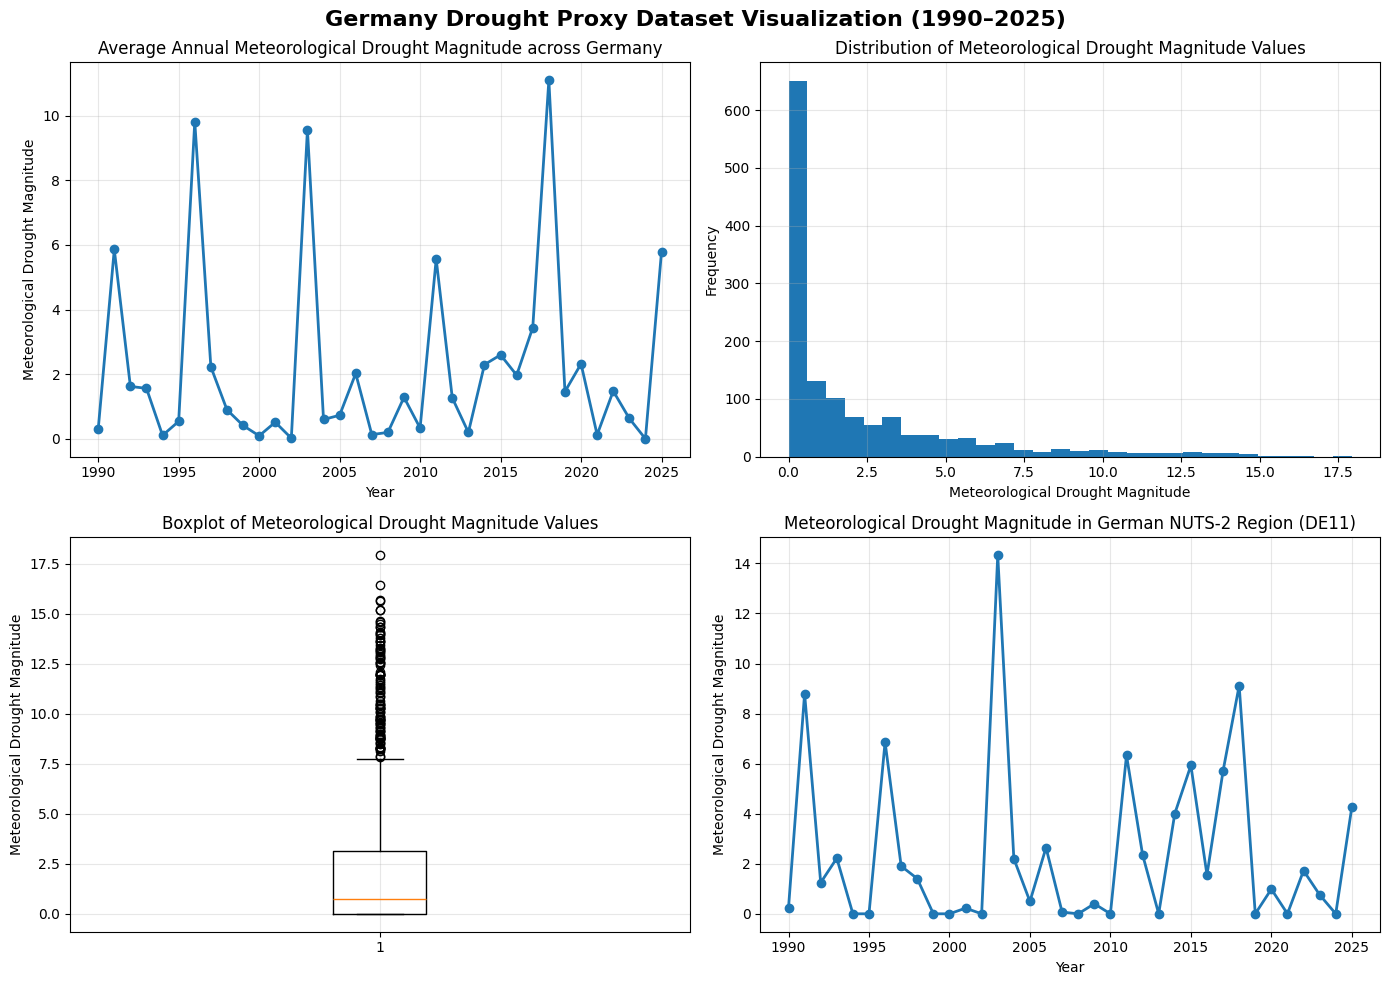

In [37]:
# =====================================================
# Visualize Germany drought proxy dataset (1990–2025)
# Four plots in one 2x2 canvas
# =====================================================

# Prepare data
germany_drought_mean = germany_drought.mean(dim="nuts")

values = germany_drought.values.flatten()
values = values[~np.isnan(values)]

example_region = (
    "DE11"
    if "DE11" in germany_drought["nuts"].values
    else germany_drought["nuts"].values[0]
)

region_drought = germany_drought.sel(nuts=example_region)

# Create 2x2 plot canvas
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Average annual drought magnitude across Germany
axes[0, 0].plot(
    germany_drought_mean["time"].dt.year,
    germany_drought_mean,
    marker="o",
    linewidth=2
)
axes[0, 0].set_title("Average Annual Meteorological Drought Magnitude across Germany")
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Meteorological Drought Magnitude")
axes[0, 0].grid(alpha=0.3)

# 2. Distribution of drought magnitude values
axes[0, 1].hist(
    values,
    bins=30
)
axes[0, 1].set_title("Distribution of Meteorological Drought Magnitude Values")
axes[0, 1].set_xlabel("Meteorological Drought Magnitude")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].grid(alpha=0.3)

# 3. Boxplot of drought magnitude values
axes[1, 0].boxplot(values)
axes[1, 0].set_title("Boxplot of Meteorological Drought Magnitude Values")
axes[1, 0].set_ylabel("Meteorological Drought Magnitude")
axes[1, 0].grid(alpha=0.3)

# 4. Example German NUTS-2 region
axes[1, 1].plot(
    region_drought["time"].dt.year,
    region_drought,
    marker="o",
    linewidth=2
)
axes[1, 1].set_title(f"Meteorological Drought Magnitude in German NUTS-2 Region ({example_region})")
axes[1, 1].set_xlabel("Year")
axes[1, 1].set_ylabel("Meteorological Drought Magnitude")
axes[1, 1].grid(alpha=0.3)

# Overall title and layout
fig.suptitle(
    "Germany Drought Proxy Dataset Visualization (1990–2025)",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Visualization Summary


The exploratory visualizations confirm that:

- Meteorological drought magnitude exhibits substantial interannual variability across Germany (1990–2025).
- High-magnitude drought years are relatively infrequent but clearly distinguishable.
- Regional differences among German NUTS-2 regions are well represented.
- The dataset provides a robust drought hazard proxy for AI-based climate risk modelling in Germany.

##### Implications for AI Model Development


The dataset will be retained in its original physical units within the raw data repository.

During feature engineering, this variable will be standardized together with the remaining climate hazard variables before training the Feed-Forward Neural Network (FFNN), while preserving the original dataset for reproducibility.

##### Next Processing Step

The Germany subset (1990–2025) has been successfully extracted.

Remaining workflow:

- Extract and preprocess the remaining climate hazard datasets.
- Merge all climate variables into a master dataset.
- Perform feature engineering and standardization.
- Build the AI-ready modelling dataset.
- Train and evaluate the Feed-Forward Neural Network (FFNN).